In [1]:
#parallel graph

from langgraph.graph import StateGraph ,START ,END
from typing import TypedDict

In [2]:
class cricketstate(TypedDict):
    Runs:int
    Balls:int
    Six:int
    Fours:int
    SR:float
    BPB:float
    BP:float
    summery:str
    

In [3]:
def calculate_sr(state:cricketstate):
    SR=(state['Runs']/state['Balls'])*100

    return {"SR":SR}



In [4]:
def calculate_bpb(state:cricketstate):
    bpb=(state['Balls'])/(state['Six']+state['Fours'])

    return {"BPB":bpb}



In [5]:
def calculate_bp(state:cricketstate):
    bp=(((state['Six']*6)+(state['Fours']*4))/state['Runs'])*100


    return {"BP":bp}

In [6]:
def generate_summery(state:cricketstate):
    summery=f"""Strike Rate : {state["SR"]}
Ball Per Boundary :{state["BPB"]} 
Boundary Percentage :{state["BP"]}
            """
    state["summery"]=summery
    return state

In [7]:
graph=StateGraph(cricketstate)

graph.add_node("calculate_sr",calculate_sr)
graph.add_node("calculate_bpb",calculate_bpb)
graph.add_node("calculate_bp",calculate_bp)
graph.add_node("generate_summery",generate_summery)

graph.add_edge(START,"calculate_sr")
graph.add_edge(START,"calculate_bpb")
graph.add_edge(START,"calculate_bp")

graph.add_edge("calculate_sr","generate_summery")
graph.add_edge("calculate_bpb","generate_summery")
graph.add_edge("calculate_bp","generate_summery")

graph.add_edge("generate_summery",END)


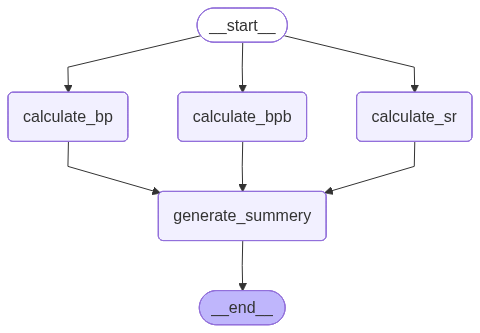

In [8]:
workflow=graph.compile()
workflow

In [9]:
initial_state={
    "Runs":130,
    "Balls":50,
    "Six":8,
    "Fours":8,
    "SR": 0.0,
    "BPB": 0.0,
    "BP": 0.0,
    "summery": ""
}
workflow.invoke(initial_state)

{'Runs': 130,
 'Balls': 50,
 'Six': 8,
 'Fours': 8,
 'SR': 260.0,
 'BPB': 3.125,
 'BP': 61.53846153846154,
 'summery': 'Strike Rate : 260.0\nBall Per Boundary :3.125 \nBoundary Percentage :61.53846153846154\n            '}